In [2]:
import pickle
import re
import sys
import warnings

warnings.filterwarnings('ignore')

sys.path = [p for p in sys.path if "positron-python" not in p]

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from sklearn.metrics import confusion_matrix

import myutils


In [3]:
workspace,experiment=myutils.workspace()
IS_FINE_TUNED = True
run = "pred_ms-2026-10-14_132744"
run = "pred_pbmc3k-2026-10-21_122719"
run = "pred_pbmc3k-2026-10-13_133425"
run = "pred_heroes-2026-10-25_172348"
save = True

In [4]:
match = re.match(r'pred_(.+?)-(.+)_.*',run)
dataset = match.group(1)
pred = 'pred-with-fine-tuning' if IS_FINE_TUNED else 'pred-wo-fine-tuning'
pred_dir = experiment / f'results/{pred}/{run}'
result_file = pred_dir / 'results.pkl'
assert pred_dir.exists()
assert result_file.exists()

if (dataset == "pbmc3k"):
    data_file = data_dir = experiment/ "data/pbmc3k_scanpy_annotated_batches.h5ad"
    celltype_col = "celltype"
if (dataset == "ms"):
    data_file = workspace / "data/ms/ms_batches.h5ad"
    celltype_col = "celltype"
if (dataset == "heroes"):
    # data_file = experiment / "data/hereos_pool7_scRNA_batches_hvg.h5ad"
    data_file = workspace / "data/scvi_pools/heroes_pool7_scRNA_batches.h5ad"
    celltype_col = "consensus_celltype"

assert data_file.exists()

In [5]:
with open(result_file, 'rb') as f:
    results = pickle.load(f)
id2type = results['id_maps']
predictions = results['predictions']
labels = results['labels']

adata = sc.read(data_file)

In [6]:
adata_test = adata[adata.obs.str_batch == '1']
adata_test.obs["predictions"] = [id2type[p] for p in predictions]

# if 'X_umap' not in adata_test.obsm and 'umap' not in adata_test.obsm:
#     sc.pp.neighbors(adata_test, n_neighbors=20, n_pcs=30)
#     sc.tl.umap(adata_test)

In [7]:
sum(adata_test.obs[celltype_col] == adata_test.obs['predictions'])

7663

In [8]:
sc.pl.umap(
        adata_test,
        color=celltype_col,
        ncols=1,
        show=False
    )
_palette = dict(
    zip(
        adata_test.obs[celltype_col].cat.categories,
        adata_test.uns[f"{celltype_col}_colors"],
    )
)
plt.close()

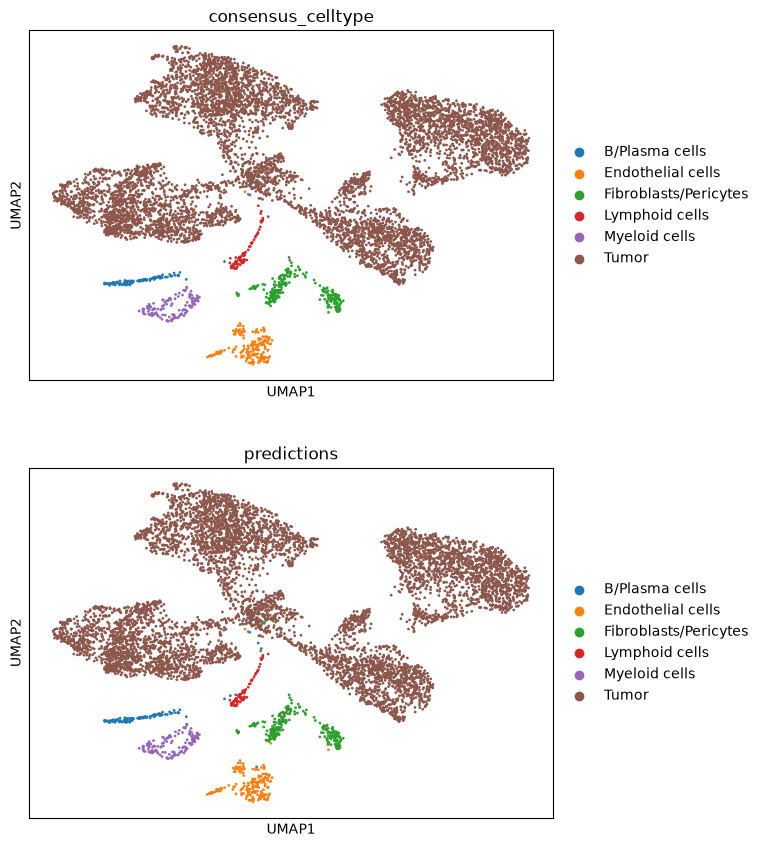

In [9]:
sc.pl.umap(
        adata_test,
        color=[celltype_col, "predictions"],
        ncols=1,
        palette=_palette,
        show=False,
    )
if save: plt.savefig(pred_dir / "results.png", dpi=300, bbox_inches="tight")

In [10]:
# def inspect_prediction(adata, celltype: str, palette: dict, save_dir: Path | None = None, celltype_col="celltype"):
#     adata_plot = adata.copy()
#     adata_plot.obs[celltype_col] = adata_plot.obs[celltype_col].astype('category')
#     if celltype in adata_plot.obs[celltype_col].cat.categories:
#         prediction_col = f"{celltype} prediction"
#         adata_plot.obs[prediction_col] = (
#             adata_plot.obs[celltype_col]
#             .astype(str)
#             .where(
#                 adata_plot.obs["celltype"] == celltype,
#                 "other",
#             )
#         )
#         mask = adata_plot.obs["celltype"] == celltype
#         # Add grey for background
#         prediction_palette = palette.copy()
#         prediction_palette["other"] = "lightgrey"
#         fig, ax = plt.subplots(figsize=(7, 7))
#         sc.pl.umap(
#             adata_plot[~mask],
#             color=prediction_col,
#             palette={"other": "lightgrey"},
#             size=15,
#             ax=ax,
#             show=False,
#         )
#         sc.pl.umap(
#             adata_plot[mask],
#             color=prediction_col,
#             palette=prediction_palette,
#             size=50,
#             ax=ax,
#             show=False,
#         )
#         if save_dir != None:
#             plt.savefig(
#                 save_dir / f"umap_prediction_{celltype.replace(' ', '_')}.png",
#                 dpi=300,
#                 bbox_inches="tight",
#             )

def inspect_prediction(adata, celltype: str, palette: dict, save_dir: Path | None = None, celltype_col="consensus_celltype", prediction_col="predictions"):
    adata_plot = adata.copy()
    
    adata_plot.obs[celltype_col] = adata_plot.obs[celltype_col].astype(str).astype('category')
    adata_plot.obs[prediction_col] = adata_plot.obs[prediction_col].astype(str).astype('category')
    
    if celltype in adata_plot.obs[celltype_col].cat.categories:
        plot_col = f"{celltype} prediction"
        
        adata_plot.obs[plot_col] = (
            adata_plot.obs[prediction_col]  
            .astype(str)
            .where(
                adata_plot.obs[celltype_col] == celltype,
                "other",
            )
        )
        
        mask = adata_plot.obs[celltype_col] == celltype
        
        adata_plot.obs[plot_col] = adata_plot.obs[plot_col].astype('category')
        
        prediction_palette = {cat: palette.get(cat, "#7f7f7f") for cat in adata_plot.obs[plot_col].cat.categories}
        prediction_palette["other"] = "lightgrey"
        
        fig, ax = plt.subplots(figsize=(7, 7))
        
        sc.pl.umap(
            adata_plot[~mask],
            color=plot_col,
            palette={"other": "lightgrey"},
            size=15,
            ax=ax,
            show=False,
            sort_order=False
        )
        
        sc.pl.umap(
            adata_plot[mask],
            color=plot_col,
            palette=prediction_palette,
            size=40,
            ax=ax,
            show=False,
            sort_order=False
        )
        
        if save_dir is not None:
            plt.savefig(
                save_dir / f"umap_prediction_{celltype.replace(' ', '_')}.png",
                dpi=300,
                bbox_inches="tight",
            )
        plt.show()


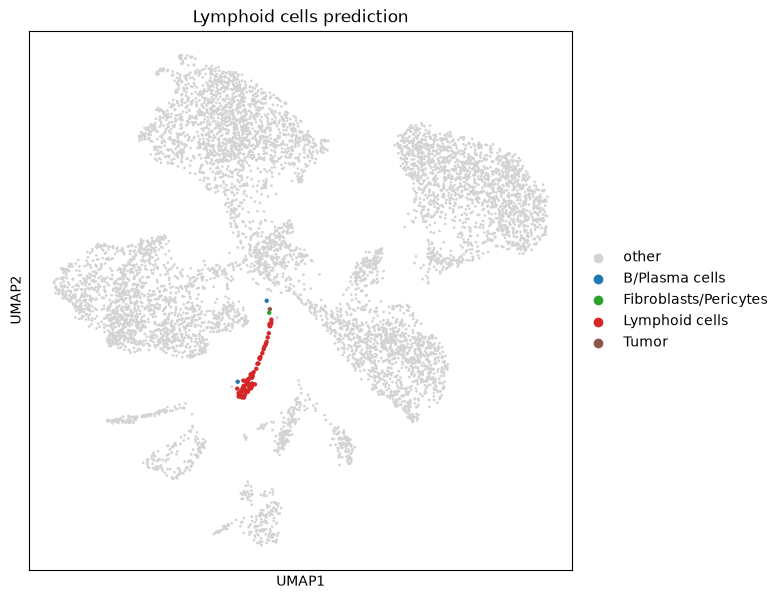

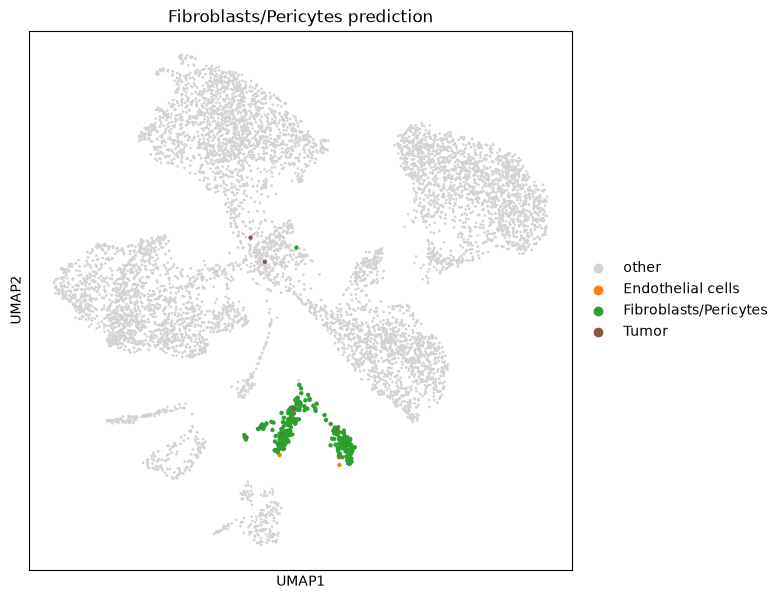

In [11]:
adata_plot = adata_test.copy()

inspect_prediction(adata_plot, 'Lymphoid cells', palette=_palette, celltype_col="consensus_celltype")
inspect_prediction(adata_plot, 'Fibroblasts/Pericytes', palette=_palette, celltype_col="consensus_celltype")

In [12]:
# myutils.inspect_prediction(adata_test, 'oligodendrocyte C', palette=_palette)
# myutils.inspect_prediction(adata_test, 'phagocyte', palette=_palette)

In [13]:
# myutils.select_celltype(adata_test, 'phagocyte', palette=_palette)
# myutils.select_prediction(adata_test, 'phagocyte', palette=_palette)

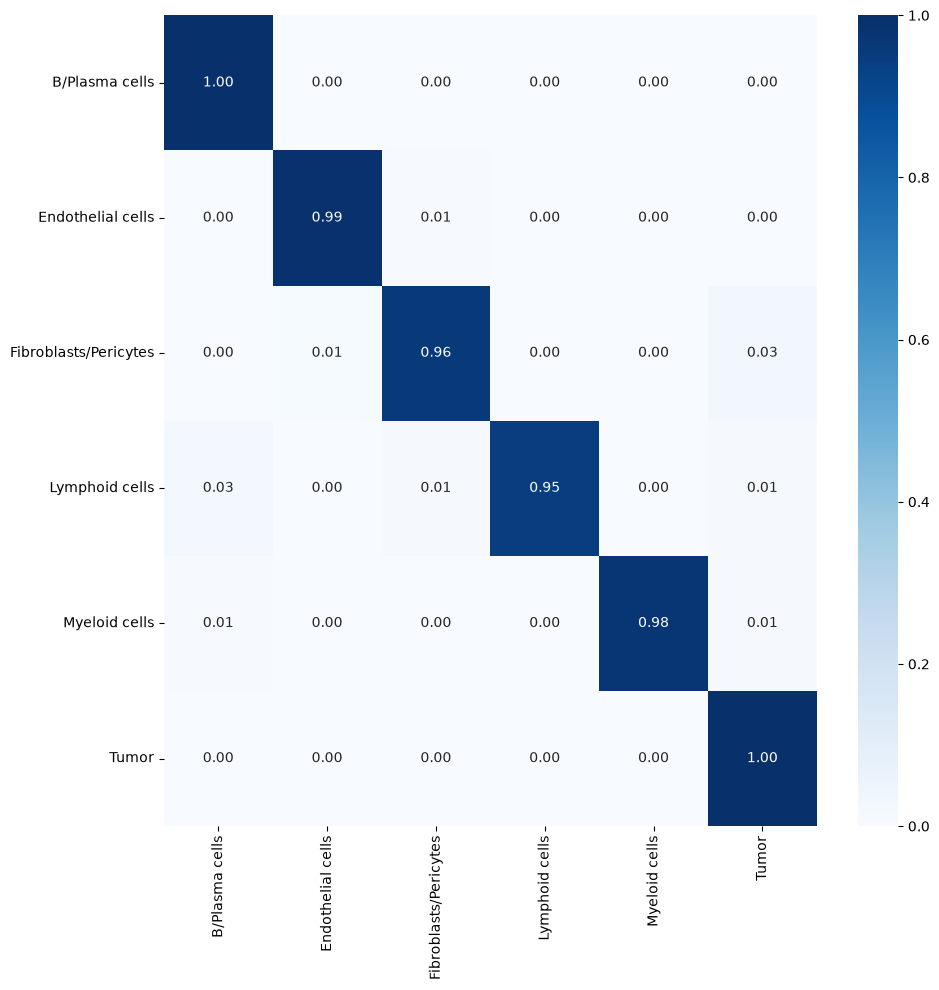

In [14]:
celltypes = adata.obs[celltype_col].unique()
celltypes = [id2type[i] for i in range(len(celltypes))]
for i in {id2type[p] for p in predictions}:
    if i not in celltypes:
        celltypes.remove(i)
cm = confusion_matrix(labels, predictions)
cm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
cm = pd.DataFrame(cm, index=celltypes[:cm.shape[0]], columns=celltypes[:cm.shape[0]])

plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues")
plt.yticks(rotation=0)
plt.tight_layout()
if save: plt.savefig(pred_dir / "confusion_matrix.png", dpi=300, )

In [15]:
cm

,B/Plasma cells,Endothelial cells,Fibroblasts/Pericytes,Lymphoid cells,Myeloid cells,Tumor
B/Plasma cells,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
Endothelial cells,0.000000,0.994318,0.005682,0.000000,0.000000,0.000000
Fibroblasts/Pericytes,0.000000,0.011583,0.957529,0.000000,0.000000,0.030888
Lymphoid cells,0.026667,0.000000,0.013333,0.946667,0.000000,0.013333
Myeloid cells,0.007299,0.000000,0.000000,0.000000,0.978102,0.014599
Tumor,0.000000,0.000000,0.001298,0.000000,0.000000,0.998702
